## 1. Импортируем датасет

In [2]:
import pandas as pd
import os
import kagglehub

path = kagglehub.dataset_download("yasserh/titanic-dataset")

print("Path to dataset files:", path)
print("hbh", os.listdir(path))

file_path = os.path.join(path, "Titanic-Dataset.csv")

df = pd.read_csv(file_path)
df.head()

Path to dataset files: C:\Users\ArtAcerNitro5\.cache\kagglehub\datasets\yasserh\titanic-dataset\versions\1
hbh ['Titanic-Dataset.csv']


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 2. Анализируем данные

In [3]:
print(df.shape)
print(df.dtypes)
print(df.isnull().sum())
print("Дубликаты: ", df.duplicated().sum())

(891, 12)
PassengerId      int64
Survived         int64
Pclass           int64
Name               str
Sex                str
Age            float64
SibSp            int64
Parch            int64
Ticket             str
Fare           float64
Cabin              str
Embarked           str
dtype: object
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64
Дубликаты:  0


мы видим очень много пропусков в колонке Age и Cabin

## 3. Визуализируем данные

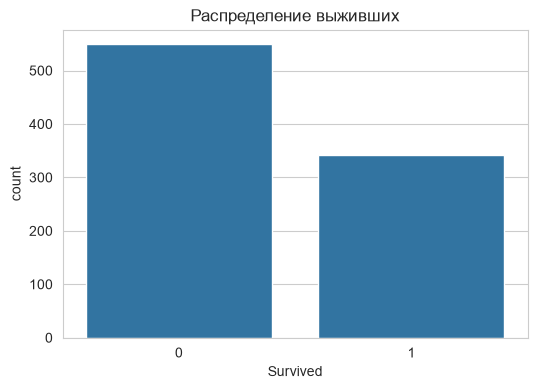

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Survived")
plt.title("Распределение выживших")
plt.show()

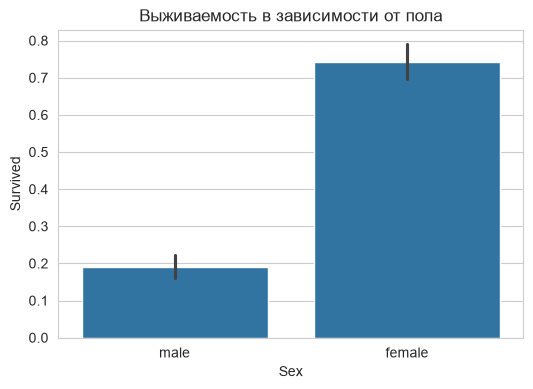

In [5]:
plt.figure(figsize=(6, 4))
sns.barplot(data=df, x="Sex" , y="Survived")
plt.title("Выживаемость в зависимости от пола")
plt.show()

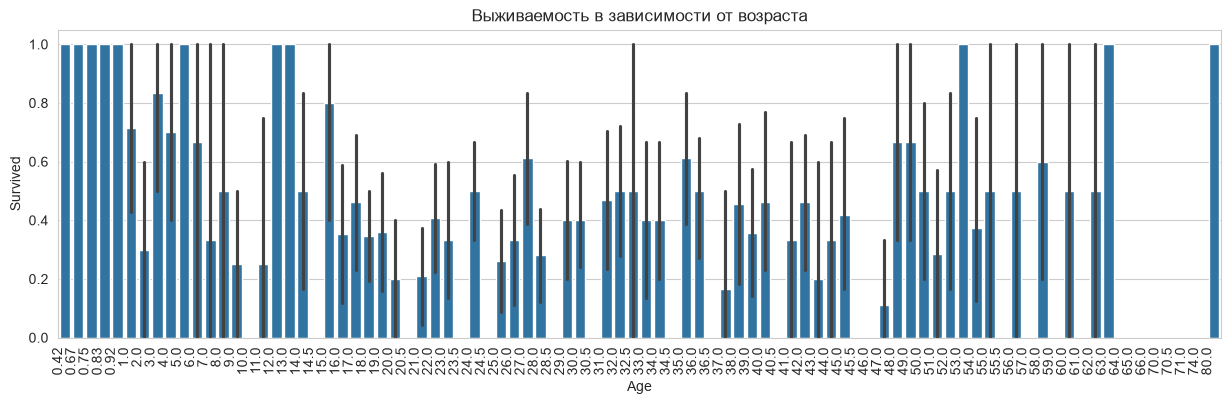

In [6]:
plt.figure(figsize=(15, 4))
sns.barplot(data=df, x="Age" , y="Survived")
plt.xticks(rotation=90, ha="right")
plt.title("Выживаемость в зависимости от возраста")
plt.show()

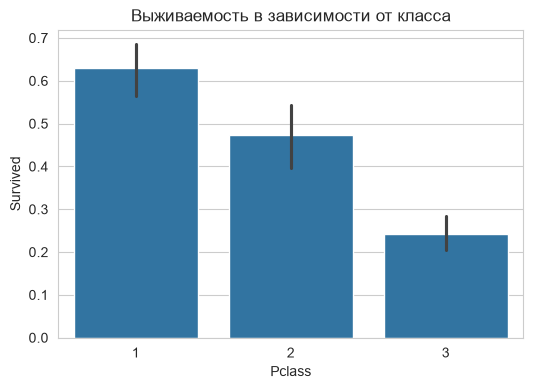

In [7]:
plt.figure(figsize=(6, 4))
sns.barplot(data=df, x="Pclass", y="Survived")
plt.title("Выживаемость в зависимости от класса")
plt.show()

## 4. Выбираем фичи

In [8]:
features = [
    "Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"
]
X = df[features].copy()
y = df["Survived"]
X.head()

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,3,male,22.0,1,0,7.2500,S
1,1,female,38.0,1,0,71.2833,C
2,3,female,26.0,0,0,7.9250,S
3,1,female,35.0,1,0,53.1000,S
4,3,male,35.0,0,0,8.0500,S


Мы исключили:
- PassengerId	это просто идентификатор пассажира, он не нужен
- Name	        не используем текстовые имена
- Ticket	    много уникальных значений билетов
- Cabin	        много пропусков

## 5. Делим датасет: train/validation/test

In [9]:
from sklearn.model_selection import train_test_split

X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.2, random_state=23, stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.2, random_state=23, stratify=y_train_val
)

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Train: (569, 7)
Validation: (143, 7)
Test: (179, 7)


## 6. Заполняем пропуски

In [10]:
X_train_p = X_train.copy()
X_val_p = X_val.copy()
X_test_p = X_test.copy()

age_median = X_train["Age"].median()
embarked_mode = X_train["Embarked"].mode()[0]

for part in [X_train_p, X_val_p, X_test_p]:
    part["Age"] = part["Age"].fillna(age_median)
    part["Embarked"] = part["Embarked"].fillna(embarked_mode)

print(X_train_p.isnull().sum())

Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    0
dtype: int64


## 7. Категориальные значения -> в числовые

In [11]:
categorical = ["Sex", "Embarked", "Pclass"]

X_train_p = pd.get_dummies(X_train_p, columns=categorical, dtype=int)
X_val_p = pd.get_dummies(X_val_p, columns=categorical, dtype=int)
X_test_p = pd.get_dummies(X_test_p, columns=categorical, dtype=int)

X_val_p = X_val_p.reindex(columns=X_train_p.columns, fill_value=0)
X_test_p = X_test_p.reindex(columns=X_val_p.columns, fill_value=0)

## 8. Scaling

Для деревьев данные уже готовы, но для SVM и KNN нужно делать Scaling

In [12]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_p)
X_val_scaled = scaler.transform(X_val_p)
X_test_scaled = scaler.transform(X_test_p)

## 9. Baseline

Accuracy: 0.6153846153846154
Precision: 0.0
Recall: 0.0
F1: 0.0


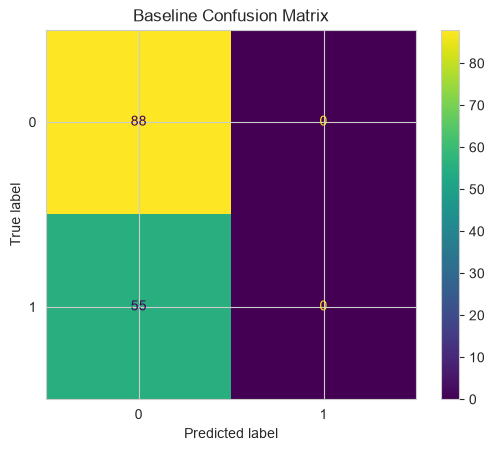

In [13]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, ConfusionMatrixDisplay
)

baseline = DummyClassifier(strategy="most_frequent")

baseline.fit(X_train_p, y_train)
baseline_pred = baseline.predict(X_val_p)

print("Accuracy:", accuracy_score(y_val, baseline_pred))
print("Precision:", precision_score(y_val, baseline_pred, zero_division=0))
print("Recall:", recall_score(y_val, baseline_pred))
print("F1:", f1_score(y_val, baseline_pred))

ConfusionMatrixDisplay.from_predictions(y_val, baseline_pred)
plt.title("Baseline Confusion Matrix")
plt.show()

## 10. Decision Tree

In [14]:
from sklearn.tree import DecisionTreeClassifier

tree = DecisionTreeClassifier(random_state=23)

tree.fit(X_train_p, y_train)

train_pred = tree.predict(X_train_p)
val_pred = tree.predict(X_val_p)

print("Depth:", tree.get_depth())
print("Train F1:", f1_score(y_train, train_pred))
print("Validation F1:", f1_score(y_val, val_pred))

Depth: 17
Train F1: 0.971830985915493
Validation F1: 0.6666666666666666


для глубины 17 дерево переобучилось => пытаемся найти оптимальную грубину дерева

## 11. Анализируем оптимальную глубину дерева

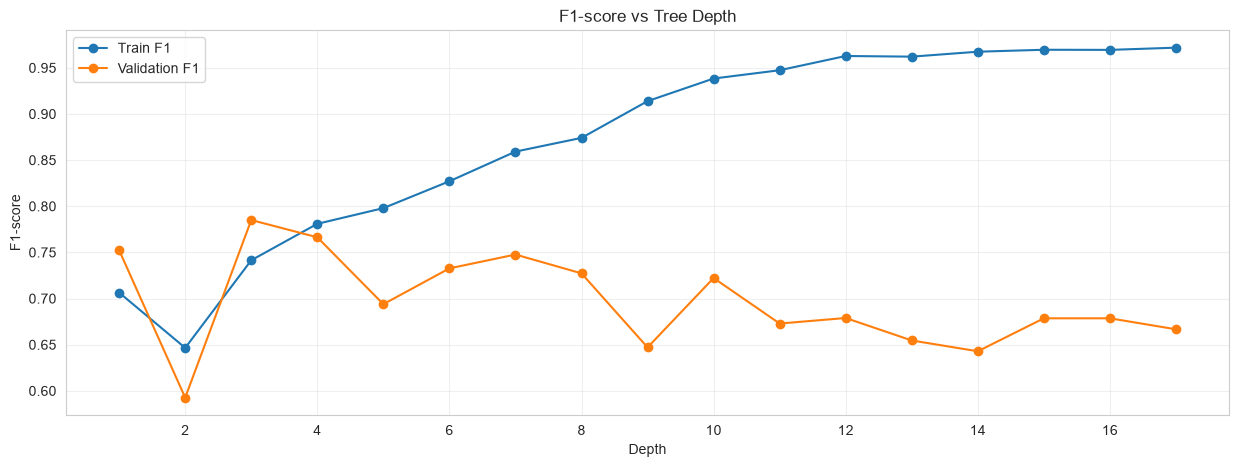

In [16]:
depths = range(1, tree.get_depth() + 1)

train_scores = []
val_scores = []

for depth in depths:
    model = DecisionTreeClassifier(
        max_depth=depth,
        random_state=23
    )

    model.fit(X_train_p, y_train)

    train_scores.append(
        f1_score(y_train, model.predict(X_train_p))
    )

    val_scores.append(
        f1_score(y_val, model.predict(X_val_p))
    )

plt.figure(figsize=(15, 5))

plt.plot(depths, train_scores, marker="o", label="Train F1")
plt.plot(depths, val_scores, marker="o", label="Validation F1")

plt.xlabel("Depth")
plt.ylabel("F1-score")
plt.title("F1-score vs Tree Depth")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [18]:
tree = DecisionTreeClassifier(
    max_depth=4,
    random_state=42
)

tree.fit(X_train_p, y_train)

tree_pred = tree.predict(X_val_p)

print("Train F1:", f1_score(y_train, tree.predict(X_train_p)))
print("Validation F1:", f1_score(y_val, tree_pred))

Train F1: 0.780952380952381
Validation F1: 0.7428571428571429
